In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import timedelta
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler





In [ ]:
# Reading the dataset
data= pd.read_csv("/content/drive/My Drive/Quiz_Dataset.csv" ,index_col='date')
 # change the date to datatime
data.index = pd.to_datetime(data.index)
data.head()

<ipython-input-3-9eec9c87d22d>:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data.index = pd.to_datetime(data.index)


,maxtp,mintp,gmin,rain,cbl,wdsp,hm,ddhm,hg,soil,pe,evap,smd_wd,smd_md,smd_pd,glorad
date,,,,,,,,,,,,,,,,
2009-10-01,12.4,8.2,6.1,0,1013.9,4.6,8,0,12,13.37,0.8,1,0.8,0.8,0.8,489
2009-10-02,15.7,8.1,5.9,0.4,1008.9,10.1,16,230,26,12.66,1.1,1.5,1.4,1.4,1.4,573
2009-10-03,13.9,7.7,10.1,0.9,1000,12.5,20,240,32,12.32,1.1,1.6,1.6,1.6,1.6,669
2009-10-04,12.4,6.6,4.1,0,1002.7,4.1,8,260,13,11.205,0.9,1.2,2.5,2.5,2.5,645
2009-10-05,16.0,5.4,1.3,0,998.4,5.7,13,150,18,12.24,1.2,1.7,3.6,3.6,3.7,1066


In [ ]:
#  My dataset consists of the following variables
#  1. rain : Precipitation amount (mm)
# 2. maxtp : Maximum Air Temperature
# 3. mintp : Minimum Air temperature (C)
# 4. gmin : 09utc Grass Minimum Temperature (C)
# 5. Soil : Mean 10cm soil temperature (C)
# 6. cbl:   -  Mean CBL Pressure (hpa)
# 7. wdsp:  -  Mean Wind Speed (kt)
# 8. hm:    -  Highest ten minute mean wind speed (kt)
# 9. ddhm:  -  Wind Direction at max 10 min mean (deg)
# 10. hg:    -  Highest Gust (kt)
# 11. pe:    -  Potential Evapotranspiration (mm)
# 12. evap:  -  Evaporation (mm)
# 13. smd_wd:-  Soil Moisture Deficits(mm) well drained
# 14. smd_md:-  Soil Moisture Deficits(mm) moderately drained
# 15. glorad:-  Global Radiation (J/cm sq.)
#  16. smd_pd:-  Soil Moisture Deficits(mm) poorly drained

In [ ]:
data.head(5)

,maxtp,mintp,gmin,rain,cbl,wdsp,hm,ddhm,hg,soil,pe,evap,smd_wd,smd_md,smd_pd,glorad
date,,,,,,,,,,,,,,,,
2009-10-01,12.4,8.2,6.1,0,1013.9,4.6,8,0,12,13.37,0.8,1,0.8,0.8,0.8,489
2009-10-02,15.7,8.1,5.9,0.4,1008.9,10.1,16,230,26,12.66,1.1,1.5,1.4,1.4,1.4,573
2009-10-03,13.9,7.7,10.1,0.9,1000,12.5,20,240,32,12.32,1.1,1.6,1.6,1.6,1.6,669
2009-10-04,12.4,6.6,4.1,0,1002.7,4.1,8,260,13,11.205,0.9,1.2,2.5,2.5,2.5,645
2009-10-05,16.0,5.4,1.3,0,998.4,5.7,13,150,18,12.24,1.2,1.7,3.6,3.6,3.7,1066


In [ ]:
# To see the issues in the dataset. What cleaning will I need to do before conducting the analysis
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5661 entries, 2009-10-01 to 2025-03-31
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   maxtp   5661 non-null   float64
 1   mintp   5661 non-null   float64
 2   gmin    5661 non-null   object 
 3   rain    5661 non-null   object 
 4   cbl     5661 non-null   object 
 5   wdsp    5661 non-null   object 
 6   hm      5661 non-null   int64  
 7   ddhm    5661 non-null   int64  
 8   hg      5661 non-null   int64  
 9   soil    5661 non-null   object 
 10  pe      5661 non-null   object 
 11  evap    5661 non-null   object 
 12  smd_wd  5661 non-null   object 
 13  smd_md  5661 non-null   object 
 14  smd_pd  5661 non-null   object 
 15  glorad  5661 non-null   object 
dtypes: float64(2), int64(3), object(11)
memory usage: 751.9+ KB


.There is issue of some features (gmin,rain,cbl,wdsp,ddhm,soil,pe,evap,smd_wd,smd_md,smd_md,glorad ) to be in object  instead of float type
 . The date should be i datetime format

In [ ]:
# List of columns that should be converted to numeric
numeric_columns = ['gmin', 'rain', 'cbl', 'wdsp', 'soil', 'pe', 'evap',
                   'smd_wd', 'smd_md', 'smd_pd', 'glorad']

# Convert each column to numeric format
for col in numeric_columns:
    # Handle potential non-numeric values by coercing errors to NaN
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Check for any resulting NaN values that might indicate conversion problems
missing_after_conversion = data.isnull().sum()
print("Missing values after conversion:", missing_after_conversion[missing_after_conversion > 0])

# Check the new data types
print(data.dtypes)

# Look at the first few rows to verify conversion worked correctly
# print(data.head())


Missing values after conversion: gmin      9
rain      5
cbl       7
wdsp      5
soil      9
pe        9
evap      9
smd_wd    9
smd_md    9
smd_pd    9
glorad    7
dtype: int64
maxtp     float64
mintp     float64
gmin      float64
rain      float64
cbl       float64
wdsp      float64
hm          int64
ddhm        int64
hg          int64
soil      float64
pe        float64
evap      float64
smd_wd    float64
smd_md    float64
smd_pd    float64
glorad    float64
dtype: object


In [ ]:
# Fill missing values using forward fill method (using previous day's values)
data_clean = data.fillna(method='ffill')

# For any remaining missing values at the beginning of the series, use backward fill
data_clean = data_clean.fillna(method='bfill')

# Verify no missing values remain
print(f"Missing values after imputation: {data_clean.isnull().sum().sum()}")

Missing values after imputation: 0


<ipython-input-7-4804e9dca65a>:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_clean = data.fillna(method='ffill')
<ipython-input-7-4804e9dca65a>:5: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_clean = data_clean.fillna(method='bfill')


In [ ]:
# Basic statistics
data_clean.describe()

,maxtp,mintp,gmin,rain,cbl,wdsp,hm,ddhm,hg,soil,pe,evap,smd_wd,smd_md,smd_pd,glorad
count,5661.000000,5661.000000,5661.000000,5661.000000,5661.00000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000,5661.000000
mean,13.495813,5.824360,3.858559,2.560113,1004.00991,8.207649,15.016252,198.429606,22.129129,10.610055,1.403515,1.983077,10.259654,9.060131,4.943915,939.021198
std,5.097440,4.708719,5.679490,4.283011,12.03161,3.636815,5.612998,82.168210,8.515965,5.117721,1.034565,1.452060,15.442445,16.423464,19.702082,694.545860
min,-7.000000,-13.400000,-17.300000,0.000000,950.70000,0.200000,0.000000,0.000000,1.000000,-1.555000,0.000000,0.000000,0.000000,-10.000000,-10.000000,25.000000
25%,10.000000,2.300000,-0.300000,0.000000,996.60000,5.500000,11.000000,150.000000,16.000000,6.407000,0.500000,0.700000,0.000000,-0.700000,-9.500000,329.000000
50%,13.400000,6.000000,4.000000,0.600000,1005.00000,7.800000,14.000000,210.000000,21.000000,10.312000,1.200000,1.700000,2.200000,2.200000,-4.700000,782.000000
75%,17.200000,9.500000,8.300000,3.300000,1012.30000,10.400000,18.000000,260.000000,27.000000,15.040000,2.100000,3.000000,15.700000,15.700000,14.200000,1427.000000
max,31.000000,17.800000,17.000000,45.800000,1036.40000,24.300000,46.000000,350.000000,67.000000,26.180000,5.700000,7.400000,86.300000,86.300000,89.400000,3076.000000


VISUALIZATION OF THE DATA

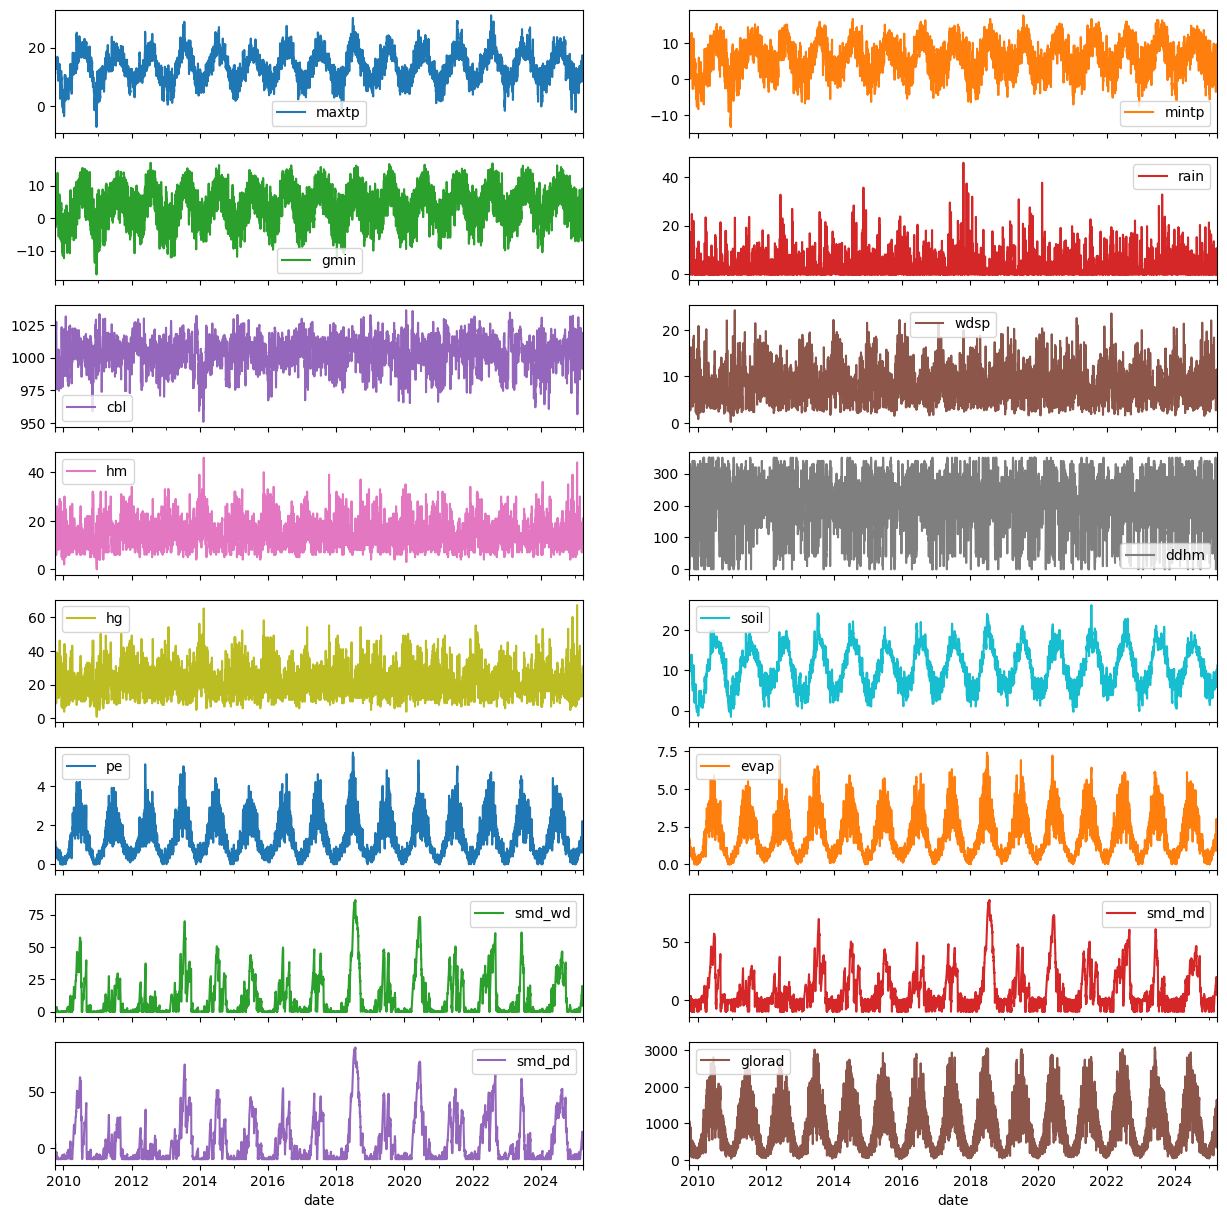

In [ ]:
data_clean.plot(subplots = True,figsize = (15,15), layout = (8,2))
plt.savefig("weather_correlation.png", dpi=300)
plt.show()

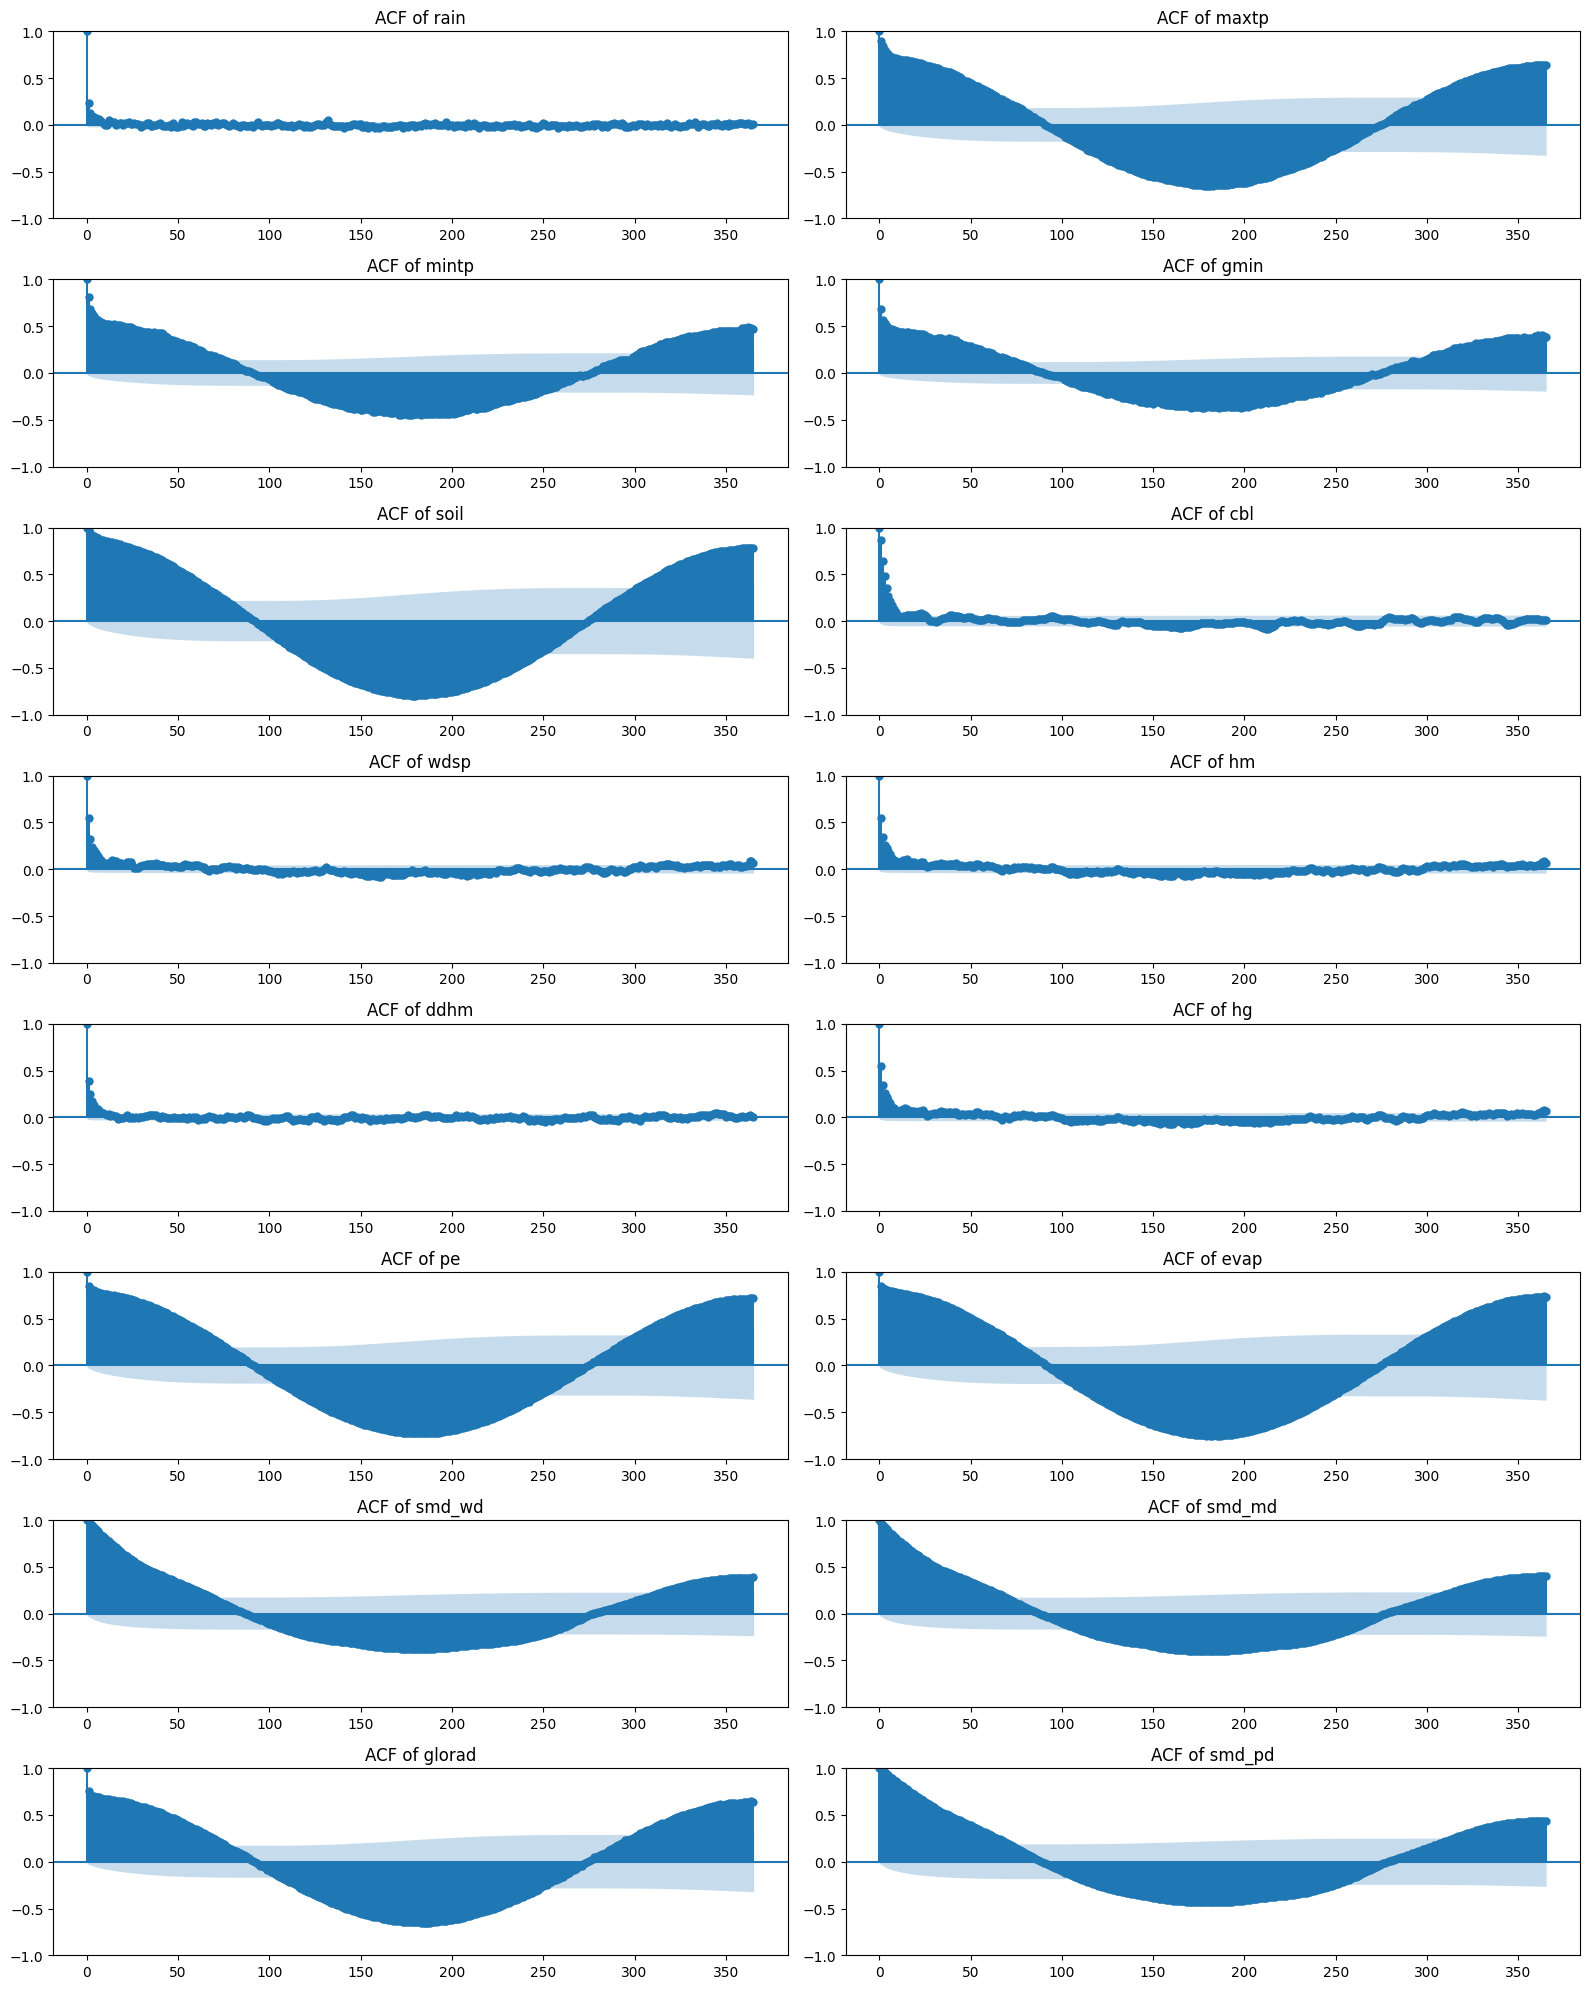

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# List of all numerical features
features = [
    'rain', 'maxtp', 'mintp', 'gmin', 'soil', 'cbl', 'wdsp', 'hm',
    'ddhm', 'hg', 'pe', 'evap', 'smd_wd', 'smd_md', 'glorad', 'smd_pd'
]

# Create subplot layout (8 rows, 2 columns = 16 plots)
fig, axes = plt.subplots(nrows=8, ncols=2, figsize=(16, 20))
axes = axes.flatten()

# Loop over features and plot ACF
for i, feature in enumerate(features):
    try:
        plot_acf(data_clean[feature].dropna(), ax=axes[i], lags=365)
        axes[i].set_title(f'ACF of {feature}')
    except Exception as e:
        axes[i].text(0.5, 0.5, f"Error: {feature}", ha='center')
        print(f"Could not plot ACF for {feature}: {e}")

# Tight layout to avoid overlap
plt.tight_layout()
plt.show()


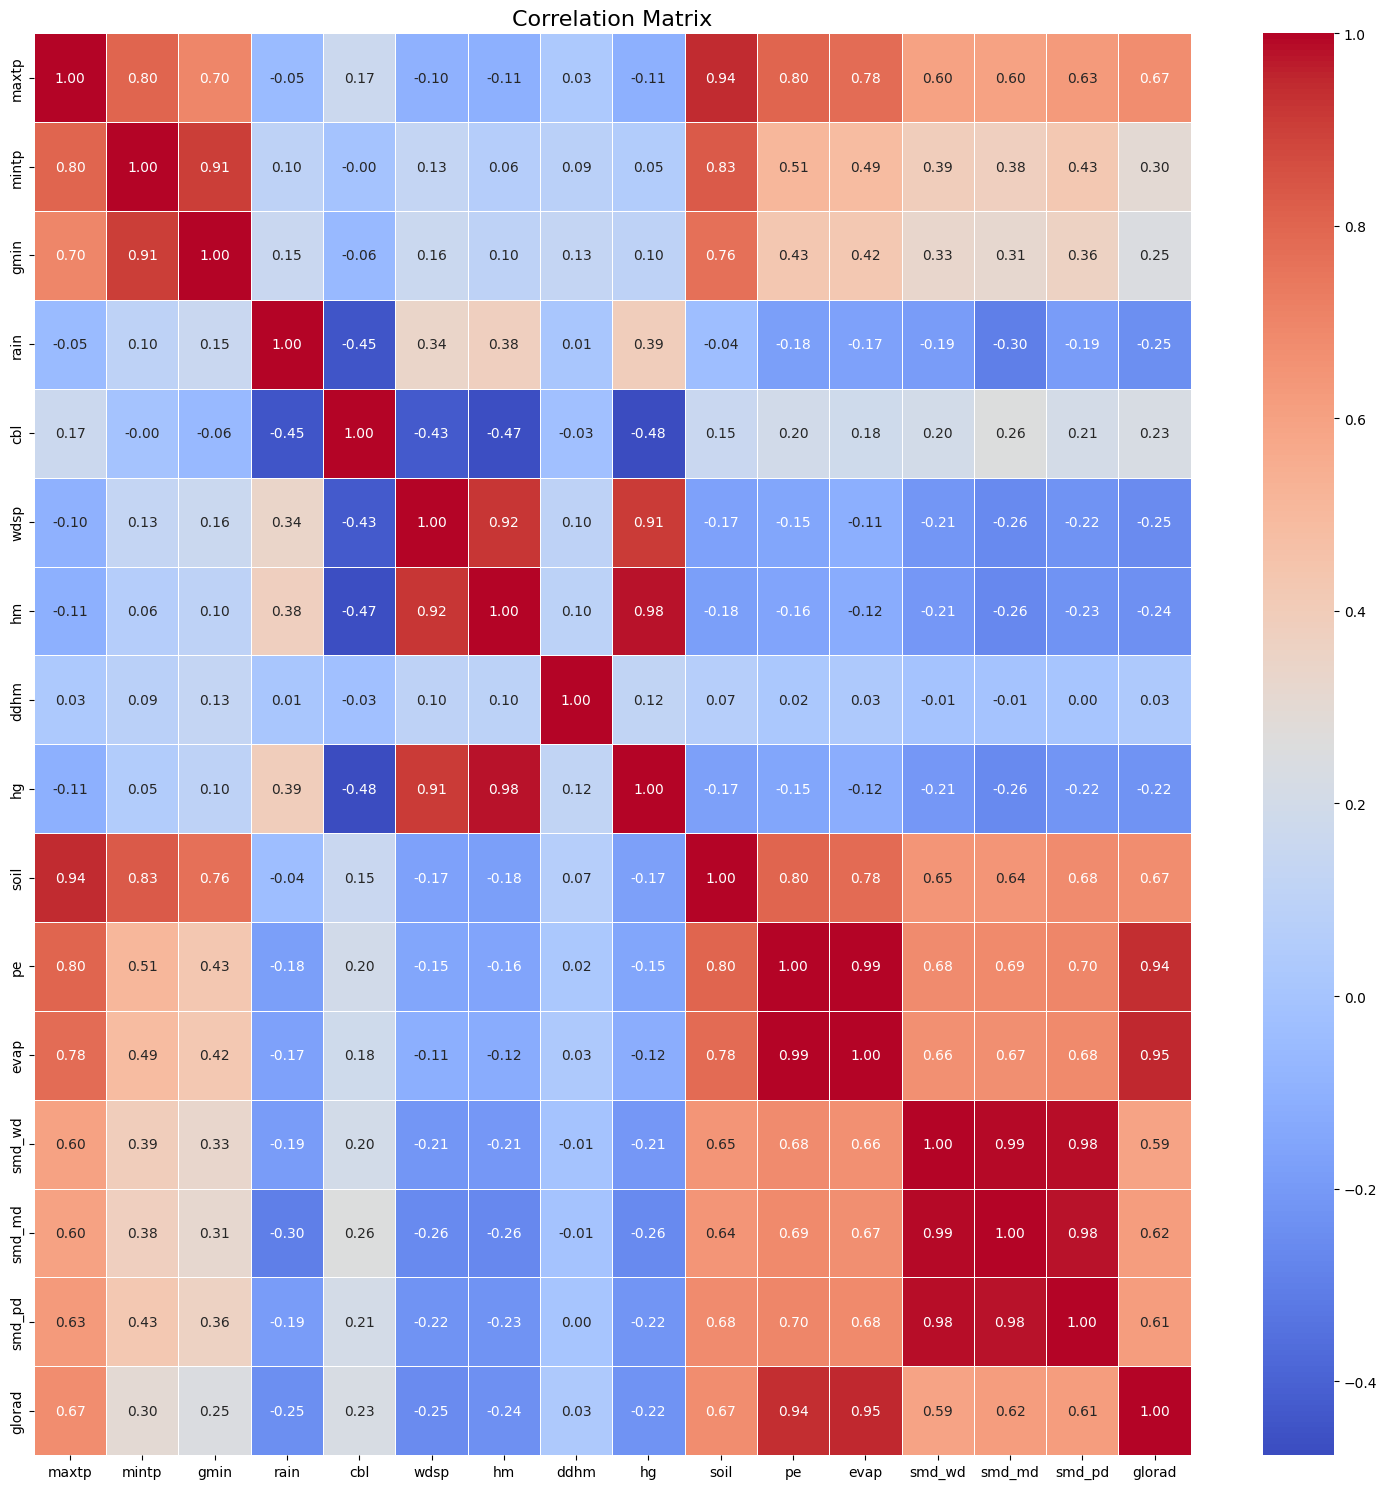

In [ ]:
# Correlation heatmap
plt.figure(figsize=(15, 15))
correlation = data_clean.corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f')
plt.title('Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

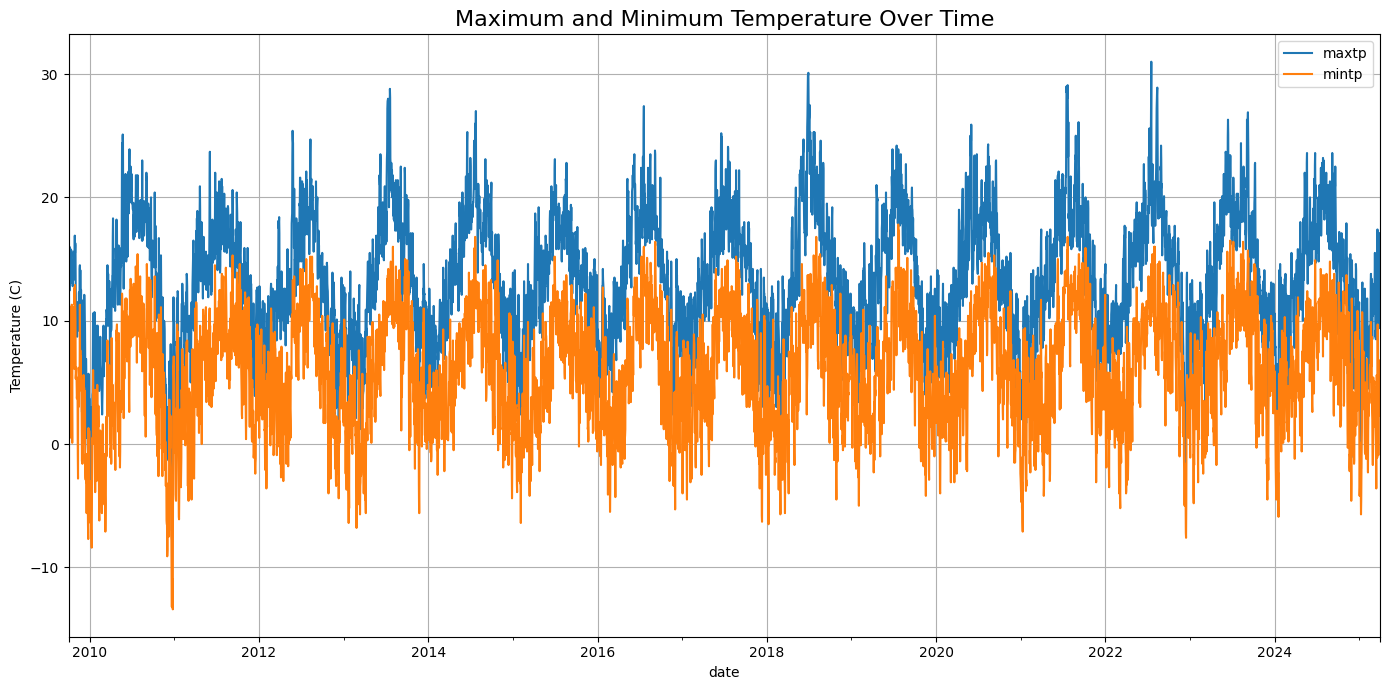

In [ ]:
# Time series plots for key variables
plt.figure(figsize=(14, 7))
data_clean[['maxtp', 'mintp']].plot(figsize=(14, 7))
plt.title('Maximum and Minimum Temperature Over Time', fontsize=16)
plt.ylabel('Temperature (C)')
plt.grid(True)
plt.tight_layout()
plt.show();

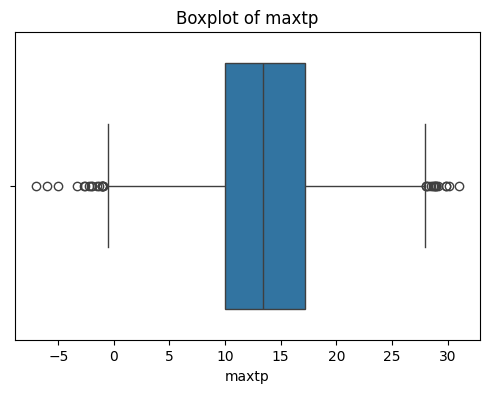

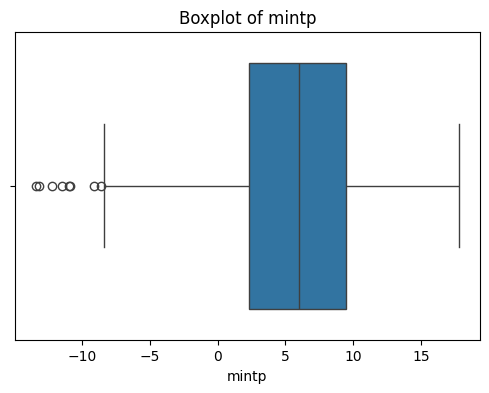

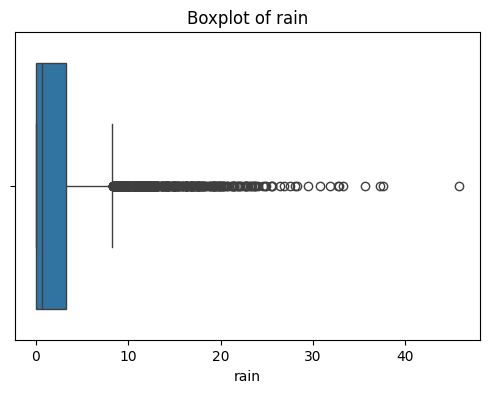

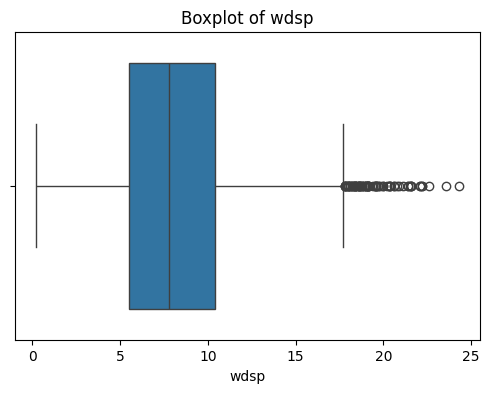

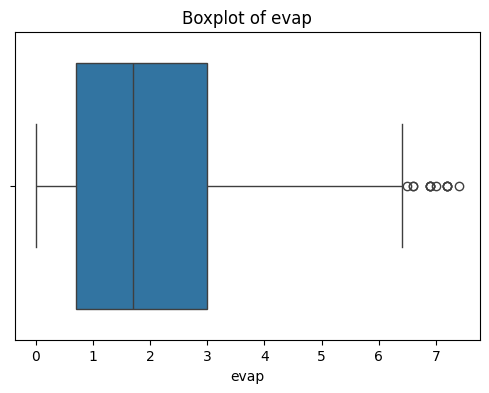

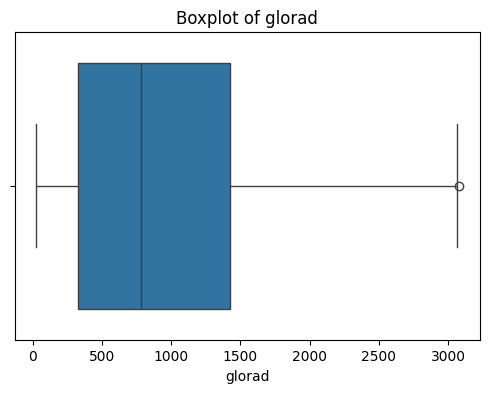

In [ ]:
# Distribution plots for a few key numerical features
num_cols = ['maxtp', 'mintp', 'rain', 'wdsp', 'evap', 'glorad']
# for col in num_cols:
#     plt.figure(figsize=(6, 4))
#     sns.histplot(data_clean[col], kde=True)
#     plt.title(f'Distribution of {col}')
#     plt.show()

#  Boxplots to detect outliers
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=data_clean[col])
    plt.title(f'Boxplot of {col}')
    plt.show()



In [ ]:

# Function to remove outliers using IQR method
def remove_outliers_iqr(data_clean):
    numeric_cols = data_clean.select_dtypes(include=['float64', 'int64']).columns
    for col in numeric_cols:
        Q1 = data_clean[col].quantile(0.25)
        Q3 = data_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        data_clean = data_clean[(data_clean[col] >= lower_bound) & (data_clean[col] <= upper_bound)]
    return data_clean

# Apply to your DataFrame
data_no_outliers = remove_outliers_iqr(data_clean)


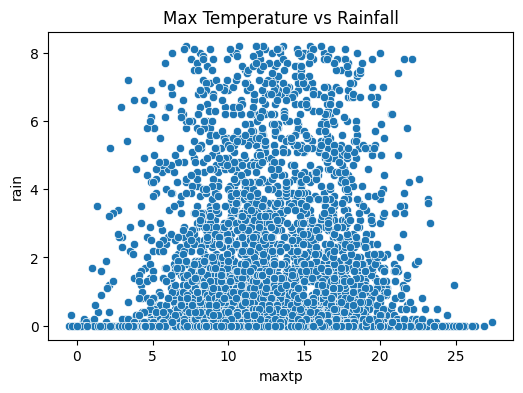

In [ ]:
# 6. Scatterplot: max temperature vs rainfall
plt.figure(figsize=(6, 4))
sns.scatterplot(x='maxtp', y='rain', data=data_no_outliers)
plt.title('Max Temperature vs Rainfall')
plt.show()

In [ ]:
# Feature engineering for time series forecasting
def create_features(data_no_outliers, target_var='maxtp'):
    """Create lag features and prepare data for forecasting models"""

    print("Creating lag features for time series forecasting...")

    # Create copy of the dataframe to avoid warnings
    data_features = data_no_outliers.copy()

    # Extract date features
    data_features['year'] = data_features.index.year
    data_features['month'] = data_features.index.month
    data_features['day'] = data_features.index.day
    data_features['dayofweek'] = data_features.index.dayofweek
    data_features['quarter'] = data_features.index.quarter

    # Create lag features for important variables
    important_vars = ['maxtp', 'mintp', 'rain', 'wdsp', 'soil', 'cbl']

    # Create lags of 1 to 7 days
    for var in important_vars:
        for lag in range(1, 8):  # 1 to 7 days lag
            data_features[f'{var}_lag_{lag}'] = data_features[var].shift(lag)

    # Create target variables for 1-day and 7-day ahead forecasts
    data_features[f'{target_var}_next_day'] = data_features[target_var].shift(-1)
    data_features[f'{target_var}_next_week'] = data_features[target_var].shift(-7)

    # Drop rows with NaN due to shifts
    data_features = data_features.dropna()

    print(f"Features created. Dataset shape: {data_features.shape}")

    return data_features



In [ ]:
# Call the function to create features
target_var = 'maxtp'  # You can change this to forecast a different variable
data_with_features = create_features(data_no_outliers, target_var)

# Split the data into features and targets
X = data_with_features.drop([f'{target_var}_next_day', f'{target_var}_next_week'], axis=1)
y_1day = data_with_features[f'{target_var}_next_day']
y_7day = data_with_features[f'{target_var}_next_week']

# Split into training and testing sets
# Use the last 20% for testing to maintain time series integrity
train_size = int(0.8 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y1_train, y1_test = y_1day[:train_size], y_1day[train_size:]
y7_train, y7_test = y_7day[:train_size], y_7day[train_size:]

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Creating lag features for time series forecasting...
Features created. Dataset shape: (4342, 65)
Training set size: (3473, 63)
Testing set size: (869, 63)


Training 1-day forecast models...
Training 7-day forecast models...

Evaluating forecasting models...

1-day Random Forest Model Performance:
RMSE: 2.1168
MAE: 1.6428
R²: 0.7967


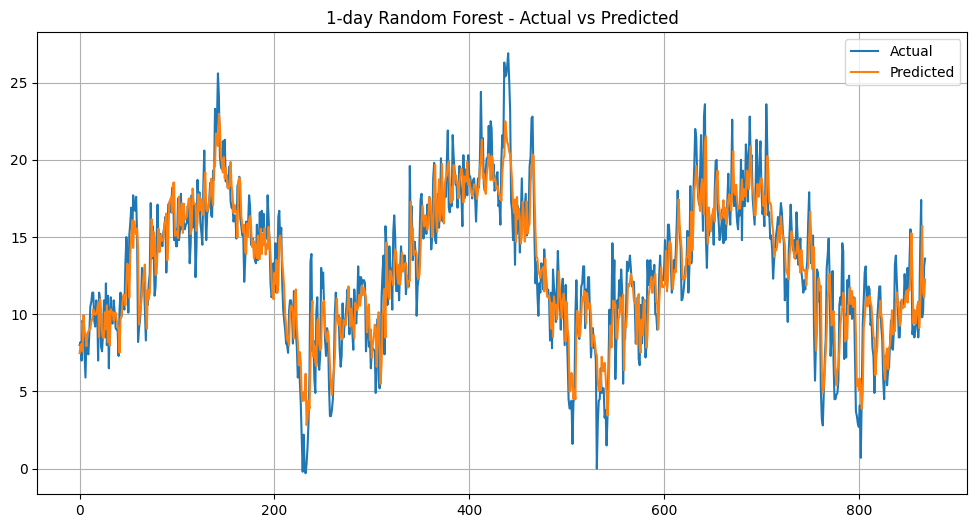


1-day XGBoost Model Performance:
RMSE: 2.0961
MAE: 1.6264
R²: 0.8007


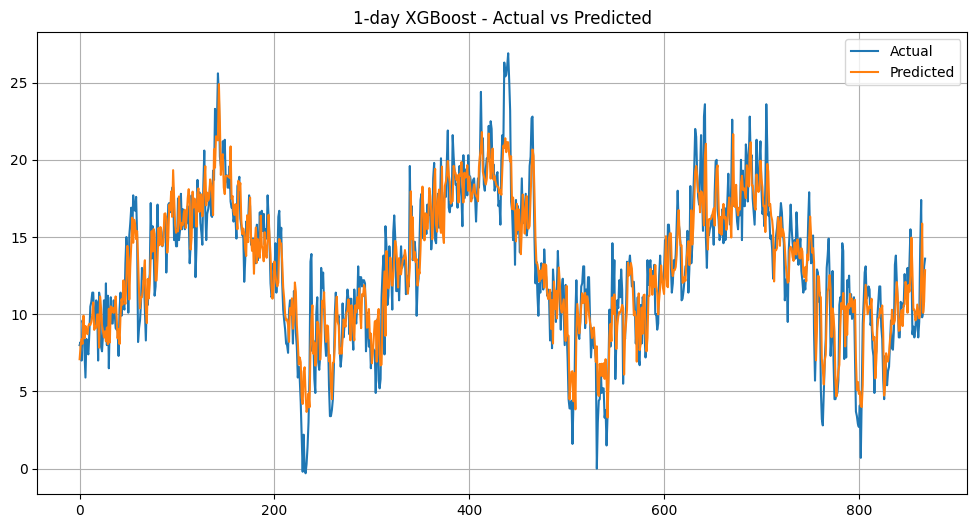


7-day Random Forest Model Performance:
RMSE: 2.9002
MAE: 2.2930
R²: 0.6164


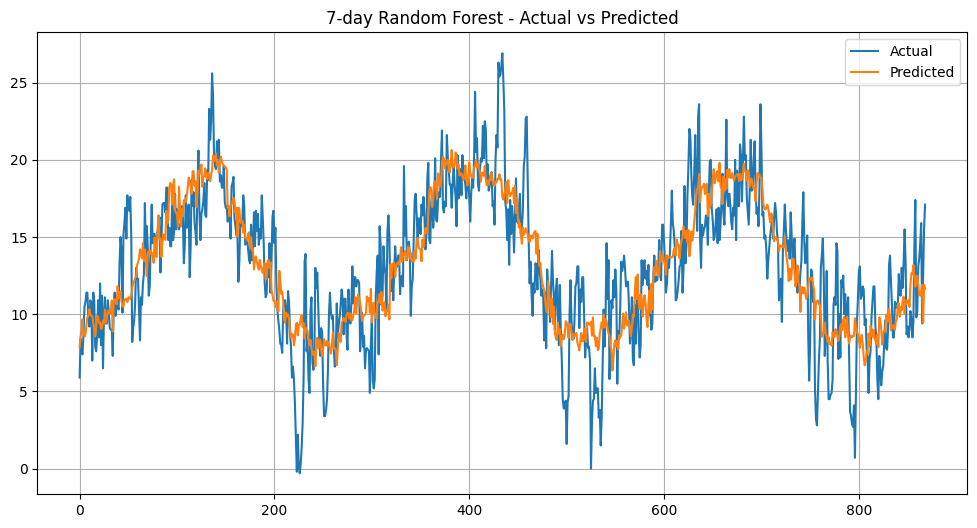


7-day XGBoost Model Performance:
RMSE: 2.9010
MAE: 2.2937
R²: 0.6162


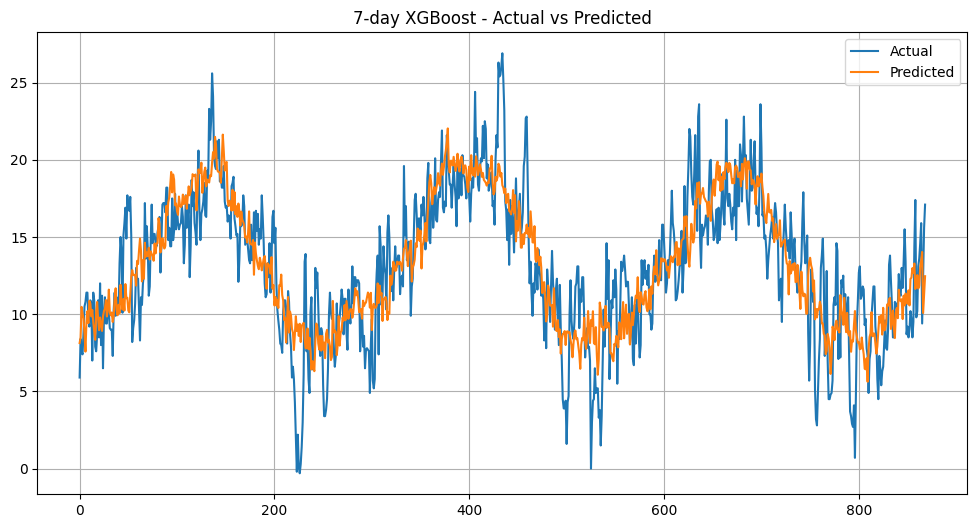


Top 10 most important features:
        Feature  Importance
0         maxtp    0.489295
9          soil    0.318914
49   soil_lag_1    0.007149
1         mintp    0.005587
4           cbl    0.005230
55   soil_lag_7    0.005088
7          ddhm    0.004846
3          rain    0.004512
58    cbl_lag_3    0.003934
28  mintp_lag_1    0.003879


In [ ]:
# Initialize models
rf_model_1day = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_7day = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_model_1day = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model_7day = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

# Train the models
print("Training 1-day forecast models...")
rf_model_1day.fit(X_train, y1_train)
xgb_model_1day.fit(X_train, y1_train)

print("Training 7-day forecast models...")
rf_model_7day.fit(X_train, y7_train)
xgb_model_7day.fit(X_train, y7_train)

# Function to evaluate models
def evaluate_model(model, X_test, y_test, model_name, forecast_horizon):
    """Evaluate model performance and print metrics"""
    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\n{forecast_horizon} {model_name} Model Performance:")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R²: {r2:.4f}")

    # Plot actual vs predicted
    plt.figure(figsize=(12, 6))
    plt.plot(y_test.values, label='Actual')
    plt.plot(y_pred, label='Predicted')
    plt.title(f'{forecast_horizon} {model_name} - Actual vs Predicted')
    plt.legend()
    plt.grid(True)
    plt.show()

    return {'rmse': rmse, 'mae': mae, 'r2': r2, 'predictions': y_pred}

# Evaluate models
print("\nEvaluating forecasting models...")
rf_1day_results = evaluate_model(rf_model_1day, X_test, y1_test, "Random Forest", "1-day")
xgb_1day_results = evaluate_model(xgb_model_1day, X_test, y1_test, "XGBoost", "1-day")
rf_7day_results = evaluate_model(rf_model_7day, X_test, y7_test, "Random Forest", "7-day")
xgb_7day_results = evaluate_model(xgb_model_7day, X_test, y7_test, "XGBoost", "7-day")

# Feature importance for best model
best_model = rf_model_1day  # You can change this based on performance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 10 most important features:")
print(feature_importance.head(10))

In [ ]:
columns_to_convert = [
    "gmin", "rain", "cbl", "wdsp", "hm", "ddhm", "hg",
    "soil", "pe", "evap", "smd_wd", "smd_md", "smd_pd", "glorad"
]

# Convert to float safely (invalid strings become NaN)
for col in columns_to_convert:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop rows with NaN in any of those columns
data.dropna(subset=columns_to_convert, inplace=True)



In [ ]:
# data[columns_to_convert].isna().sum()


In [ ]:
data.shape

(5648, 17)

In [ ]:
# Convert the columns () to float type
# data["gmin"] = data["gmin"].astype(float)
# data["rain"] = data["rain"].astype(float)
# data["cbl"] = data["cbl"].astype(float)
# data["wdsp"] = data["wdsp"].astype(float)
# data["hm"] = data["hm"].astype(float)
# data["ddhm"] = data["ddhm"].astype(float)
# data["hg"] = data["hg"].astype(float)
# data["soil"] = data["soil"].astype(float)
# data["pe"] = data["pe"].astype(float)
# data["evap"] = data["evap"].astype(float)
# data["smd_wd"] = data["smd_wd"].astype(float)
# data["smd_md"] = data["smd_md"].astype(float)
# data["smd_pd"] = data["smd_pd"].astype(float)
# data["glorad"] = data["glorad"].astype(float)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5648 entries, 0 to 5660
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    5648 non-null   object 
 1   maxtp   5648 non-null   float64
 2   mintp   5648 non-null   float64
 3   gmin    5648 non-null   float64
 4   rain    5648 non-null   float64
 5   cbl     5648 non-null   float64
 6   wdsp    5648 non-null   float64
 7   hm      5648 non-null   int64  
 8   ddhm    5648 non-null   int64  
 9   hg      5648 non-null   int64  
 10  soil    5648 non-null   float64
 11  pe      5648 non-null   float64
 12  evap    5648 non-null   float64
 13  smd_wd  5648 non-null   float64
 14  smd_md  5648 non-null   float64
 15  smd_pd  5648 non-null   float64
 16  glorad  5648 non-null   float64
dtypes: float64(13), int64(3), object(1)
memory usage: 794.2+ KB
